# Adsorption Energy Distribution of As(III) on Manganese Ferrite ($\text{MnFe}_2\text{O}_4$) Nanoparticles

**Authors:** López‑Luna, J.$^{1*}$, Vázquez-Hipólito, V.$^{2}$, Ramírez‑Montes, L.E.$^{3}$, Martinez‑Vargas, S.$^{4}$, Martínez, I.A.$^{5}$, Mijangos‑Ricardez, O.F.$^{3}$, Solís‑Domínguez, F.A.$^{6}$, Cuevas‑Díaz, M.C.$^{7}$

***

$^{1}$ Independent Researcher; $^{2}$ Universidad Tecnológica de la Mixteca, Oaxaca, México; $^{3}$ Universidad de la Sierra Juárez, Oaxaca, México;
$^{4}$ Universidad Autónoma del Carmen, Campeche, México; $^{5}$ Cinvestav-Saltillo, Coahuila, México; $^{6}$ Universidad Autónoma de Baja California, Baja California, México; $^{7}$ Universidad Veracruzana, Veracruz, México.

$^{*}$ **Corresponding author:** jlol_24@hotmail.com

---

### How to Cite This Notebook

If you utilize this specific pipeline for Adsorption Energy Distribution calculations, please cite this software component as:

> **Specific Software Component:** López-Luna, J., Vázquez-Hipólito, V., Ramírez-Montes, L.E. et al. (2026). Adsorption Energy Distribution of As(III) on Manganese Ferrite ($\text{MnFe}_2\text{O}_4$) Nanoparticles [Jupyter Notebook Software]. Zenodo. https://doi.org

---

### Related Repositories & Foundational Studies

Additionally, please ensure proper attribution to the foundational experimental datasets, kinetics, and isotherm modeling framework by citing the following works:

> **General Software Repository:** López-Luna, J., Vázquez-Hipólito, V., Ramírez-Montes, L.E. et al. (2026). Adsorption Behavior of Trivalent Arsenic on Manganese Ferrite Nanoparticles: Kinetics, Isotherms, and Rate-Limiting Steps [Jupyter Notebook Software]. Zenodo. Version v1 10.5281/zenodo.22695744; Version 2.0.0 10.5281/zenodo.23172980.

**Foundational Study:** López-Luna, J., Ramírez-Montes, L.E., Martinez-Vargas, S. et al. Linear and nonlinear kinetic and isotherm adsorption models for arsenic removal by manganese ferrite nanoparticles. *SN Appl. Sci.* **1**, 950 (2019). https://doi.org

## 1. Theoretical Models & Mathematical Foundations

The heterogeneous adsorption surface is evaluated by modeling the global experimental isotherm ($q_e$) as a continuous integration of local homogeneous adsorption sites. This is mathematically described by the **Fredholm Integral Equation of the First Kind**:

$$q_e(C_e) = \int_{E_{min}}^{E_{max}} \theta(E, C_e) f(E) dE$$

Where:
*   $C_e$ is the equilibrium concentration of $\text{As(III)}$ ($\text{mg/L}$).
*   $\theta(E, C_e)$ represents the **local adsorption kernel** (fractional site coverage at a specific energy).
*   $f(E)$ is the continuous **Adsorption Energy Distribution (AED)** function ($(\text{mg/g})/(\text{kJ/mol})$) to be resolved.
*   $E$ represents the interaction adsorption energy ($\text{kJ/mol}$).

The relationship between the local affinity constant ($K_L$) and the interaction energy ($E$) is given by the Arrhenius-type equation:

$$K_L = K_0 \exp\left(\frac{E}{RT}\right)$$

Where $K_0$ is the pre-exponential scale factor related to the chemical affinity ($\text{L/mg}$), $R$ is the universal gas constant ($8.314 \times 10^{-3} \text{ kJ/(mol}\cdot\text{K)}$), and $T$ is the operational temperature ($\text{K}$).

### Local Kernel Configurations

This pipeline incorporates two distinct local adsorption models to construct the Fredholm kernel matrix ($\mathbf{K}$):

#### 1. Ideal Langmuir Local Kernel
The classic Langmuir model assumes a structurally homogeneous surface with identical, independent active sites and zero lateral interactions between adsorbed species:

$$\theta(E, C_e) = \frac{K_L C_e}{1 + K_L C_e} = \frac{K_0 \exp\left(\frac{E}{RT}\right) C_e}{1 + K_0 \exp\left(\frac{E}{RT}\right) C_e}$$

#### 2. Non-Ideal Fowler-Guggenheim Local Kernel
The Fowler-Guggenheim model extends the Langmuir formulation by introducing a lateral interaction parameter ($w$, $\text{kJ/mol}$) to account for the energetic interactions between adjacent molecules on the surface. The local fractional coverage ($\theta$) becomes an implicit function that must be solved numerically:

$$K_L C_e = \frac{\theta}{1 - \theta} \exp\left(-\frac{2w\theta}{RT}\right)$$

*   If $w > 0$, the interactions between adsorbed $\text{As(III)}$ species are **attractive** (cooperative adsorption).
*   If $w < 0$, the interactions are **repulsive**.
*   If $w = 0$, the equation simplifies identically back to the ideal Langmuir model.

---

### References
*   [1] Cerofolini, G. F. (1974). Misconceptions in the theory of physical adsorption on heterogeneous surfaces. *Surface Science*, 47(2), 469-475.
*   [2] Langmuir, I. (1918). The adsorption of gases on plane surfaces of glass, mica and platinum. *Journal of the American Chemical Society*, 40(9), 1361-1403.
*   [3] Fowler, R. H., & Guggenheim, E. A. (1939). *Statistical Thermodynamics*. Cambridge University Press, London.


## 2. Environment Setup & Data Ingestion

In this section, the required scientific python libraries are imported for numerical analysis, matrix optimization, integration, and high-resolution plotting. The notebook loads the experimental equilibrium dataset (`dataeq.csv`) containing equilibrium concentration (\(C_e\), mg/L) and adsorption capacity (\(q_e\), mg/g). 

A safety operational correction is applied to \(C_e\) vectors to eliminate mathematical indeterminacy during continuous logarithmic or exponential execution in the thermodynamic framework.


In [1]:
import os
import pandas as pd
import numpy as np
from scipy.optimize import nnls
from scipy.integrate import simpson
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

# =====================================================================
# 1. EXPERIMENTAL DATA LOADING & CLEANING
# =====================================================================
csv_filename = "dataeq.csv"
if not os.path.exists(csv_filename):
    raise FileNotFoundError(f"Error: The file '{csv_filename}' was not found in the directory.")

df_eq = pd.read_csv(csv_filename)

# Extracting numerical vectors from your dataset
Ce_raw = df_eq["Ce"].values.astype(float)
qe = df_eq["qe"].values.astype(float)

# Safety correction to avoid numerical indeterminacy (Ce <= 0)
Ce = np.where(Ce_raw <= 0, 1e-8, Ce_raw)

# Universal physical constants
R = 8.314e-3  # Gas constant in kJ/(mol·K)
T = 298.15    # Operational temperature in Kelvin (25 °C)

print("Status: Libraries imported and experimental dataset loaded successfully.")
print(f"Loaded {len(Ce)} experimental data points.")


Status: Libraries imported and experimental dataset loaded successfully.
Loaded 5 experimental data points.


## 3. Discretization of the Energy Spectrum & Kernel Generation

In this section, the continuous interaction energy spectrum ($E$) is discretized into $120$ homogeneous sub-intervals across an operational window from $0.0$ to $40.0 \text{ kJ/mol}$. 

The code evaluates the Fredholm matrix ($\mathbf{K}$) using the selected non-ideal **Fowler-Guggenheim implicit kernel**. This step requires numerically computing the local fractional coverage ($\theta$) by minimizing the implicit affinity expression for each distinct concentration and energy element.


In [2]:
# =====================================================================
# 2. THERMODYNAMIC MODEL SELECTION (KERNEL CONFIGURATION)
# =====================================================================
KERNEL_TYPE = 'fowler-guggenheim'  
w_interaction = 1.0  # Lateral interaction parameter 'w' (kJ/mol)
K0 = 0.01            # Pre-exponential scale factor for chemical affinity

# =====================================================================
# 3. ENERGY SPECTRUM DISCRETIZATION (AED X-Axis)
# =====================================================================
E_min, E_max = 0.0, 40.0
num_E_points = 120  # Total sub-intervals for numerical integration
E_vector = np.linspace(E_min, E_max, num_E_points)

# =====================================================================
# 4. KERNEL MATRIX CONSTRUCTION (Fredholm Integral Equation)
# =====================================================================
print(f"Constructing local base matrix using model: {KERNEL_TYPE}...")
Kernel = np.zeros((len(Ce), num_E_points))

for j, E in enumerate(E_vector):
    # Calculate base affinity constant for this specific energy level
    Kl_base = K0 * np.exp(E / (R * T))
    
    if KERNEL_TYPE == 'langmuir':
        Kernel[:, j] = (Kl_base * Ce) / (1 + Kl_base * Ce)
        
    elif KERNEL_TYPE == 'fowler-guggenheim':
        for i, c_val in enumerate(Ce):
            theta_space = np.linspace(0.001, 0.999, 1000)
            # Minimize error of the implicit Fowler-Guggenheim equality
            fg_error = np.abs(Kl_base * c_val - (theta_space / (1 - theta_space)) * np.exp(-2 * w_interaction * theta_space / (R * T)))
            optimal_theta = theta_space[np.argmin(fg_error)]
            Kernel[i, j] = optimal_theta

print("Kernel matrix built successfully. Matrix shape:", Kernel.shape)


Constructing local base matrix using model: fowler-guggenheim...
Kernel matrix built successfully. Matrix shape: (5, 120)


## 4. Inverse Problem Resolution & Adsorption Regime Partitioning

The vector representing the continuous active site density $f(E)$ is calculated by deploying the **Non-Negative Least Squares (NNLS)** optimization routine. This approach avoids mathematical artifacts like unphysical negative site numbers.

To quantitatively evaluate the adsorption mechanisms:
*   **Total Capacity ($Q_m$):** Computed via integration over the full spectrum using Simpson's 1/3 rule.
*   **Regime Partitioning:** Sub-divided at a standard thermodynamic boundary of **$E = 8.0 \text{ kJ/mol}$**. Regions below this threshold represent low-energy physical interactions (physisorption/pores), whereas domains above denote specific chemical coordinate bonds.


In [3]:
# =====================================================================
# 5. INVERSE PROBLEM RESOLUTION (Non-Negative Least Squares)
# =====================================================================
print("Solving the optimal adsorption energy distribution...")
# f_dist stores the calculated site density for each energy level
f_dist, residue = nnls(Kernel, qe)

# Matrix multiplication to obtain predicted qe values
qe_predicted = np.dot(Kernel, f_dist)

# =====================================================================
# 6. STATISTICAL GOODNESS-OF-FIT METRICS
# =====================================================================
# Coefficient of Determination (R²)
ss_res = np.sum((qe - qe_predicted) ** 2)
ss_tot = np.sum((qe - np.mean(qe)) ** 2)
r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0

# Non-linear Chi-Squared Test (X²)
chi_squared = np.sum(((qe - qe_predicted) ** 2) / (qe_predicted + 1e-8))

# =====================================================================
# 7. QUANTITATIVE ANALYSIS VIA SIMPSON'S INTEGRATION
# =====================================================================
print("\n--- ACTIVE SITES REPOSITORY (RESULTS) ---")
total_area = simpson(y=f_dist, x=E_vector)
print(f"Total Integrated Capacity (Global Qm): {total_area:.2f} mg/g")
print(f"Goodness of Fit -> R²: {r_squared:.4f} | Chi-Squared (X²): {chi_squared:.4f}")

# Detect local maxima (peaks)
peaks, _ = find_peaks(f_dist, height=0.5)

# Partition at E = 8.0 kJ/mol (Physical vs Chemical Adsorption boundary)
idx_split = np.searchsorted(E_vector, 8.0)
area_physisorption = simpson(y=f_dist[:idx_split], x=E_vector[:idx_split])
area_chemisorption = simpson(y=f_dist[idx_split:], x=E_vector[idx_split:])

pct_phys = (area_physisorption / total_area) * 100 if total_area > 0 else 0
pct_chem = (area_chemisorption / total_area) * 100 if total_area > 0 else 0

print(f"-> Low-Energy Sites (E < 8 kJ/mol - Physisorption/Pores): {pct_phys:.1f}% of total capacity.")
print(f"-> High-Energy Sites (E >= 8 kJ/mol - Specific Chemisorption): {pct_chem:.1f}% of total capacity.")

if len(peaks) > 0:
    print("\nDetected Peak Maxima:")
    for p in peaks:
        print(f"   Site at E = {E_vector[p]:.1f} kJ/mol | Density f(E) = {f_dist[p]:.2f}")
print("-----------------------------------------\n")

# Export numerical raw profile data for Origin/Prism software
df_output = pd.DataFrame({"Energy_kJ_mol": E_vector, "Site_Density_fE": f_dist})
df_output.to_csv("aed_profile_data.csv", index=False)


Solving the optimal adsorption energy distribution...

--- ACTIVE SITES REPOSITORY (RESULTS) ---
Total Integrated Capacity (Global Qm): 17.98 mg/g
Goodness of Fit -> R²: 1.0000 | Chi-Squared (X²): 0.0000
-> Low-Energy Sites (E < 8 kJ/mol - Physisorption/Pores): 80.0% of total capacity.
-> High-Energy Sites (E >= 8 kJ/mol - Specific Chemisorption): 20.0% of total capacity.

Detected Peak Maxima:
   Site at E = 2.0 kJ/mol | Density f(E) = 43.46
   Site at E = 4.0 kJ/mol | Density f(E) = 20.75
   Site at E = 12.1 kJ/mol | Density f(E) = 3.25
   Site at E = 20.2 kJ/mol | Density f(E) = 8.26
   Site at E = 39.0 kJ/mol | Density f(E) = 4.50
-----------------------------------------



## 5. Visual Diagnostics & Graphics Generation

A dual-panel plot is rendered and exported to disk in high resolution (`aed_results.png`, 300 DPI):
1. **Left Panel (AED Landscape):** Traces continuous site density \(f(E)\) vs interaction energy (\(E\)). It visually delineates the physisorption and chemisorption zones using the 8.0 kJ/mol threshold.
2. **Right Panel (Fit Validation):** Correlates raw experimental coordinates against the continuous back-calculated theoretical curve to validate optimization accuracy.


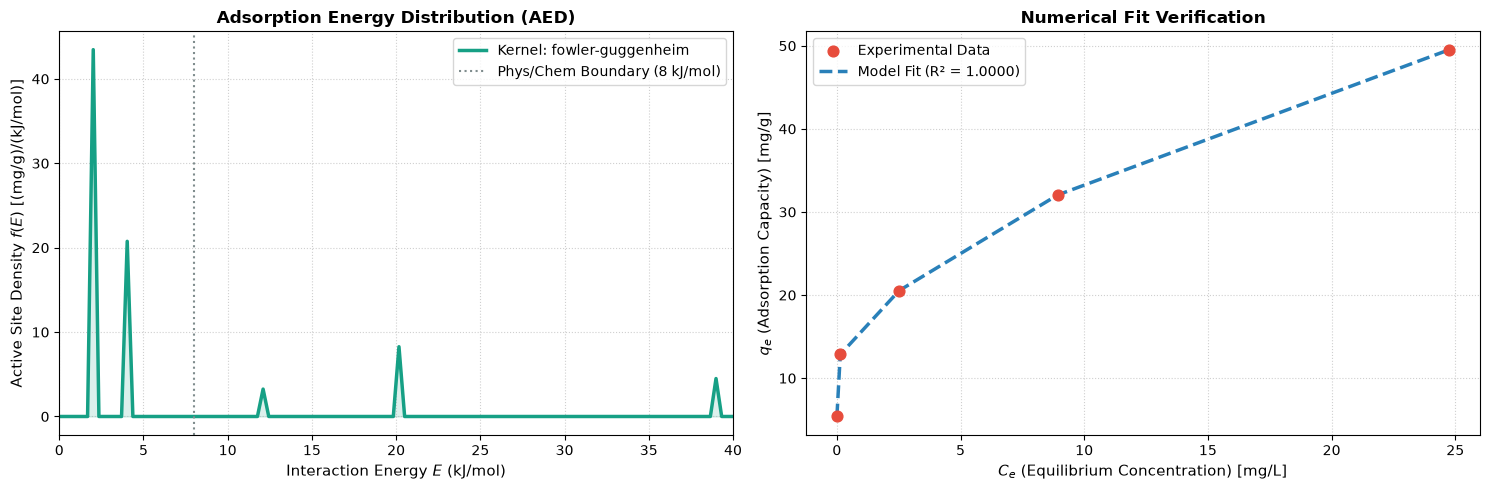

In [5]:
# =====================================================================
# 8. RESULTS VISUALIZATION & HIGH-RESOLUTION SAVE
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Graph 1: Adsorption Energy Distribution (AED) Profile Plot
ax1.plot(E_vector, f_dist, color='#16a085', linewidth=2.5, label=f'Kernel: {KERNEL_TYPE}')
ax1.fill_between(E_vector, f_dist, color='#16a085', alpha=0.15)
ax1.axvline(x=8.0, color='#7f8c8d', linestyle=':', label='Phys/Chem Boundary (8 kJ/mol)')
ax1.set_title('Adsorption Energy Distribution (AED)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Interaction Energy $E$ (kJ/mol)', fontsize=11)
ax1.set_ylabel('Active Site Density $f(E)$ [(mg/g)/(kJ/mol)]', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_xlim(E_min, E_max)
ax1.legend()

# Graph 2: Statistical Fit Verification Plot
ax2.scatter(Ce, qe, color='#e74c3c', s=60, zorder=3, label='Experimental Data')
ax2.plot(Ce, qe_predicted, color='#2980b9', linestyle='--', linewidth=2.5, label=f'Model Fit (R² = {r_squared:.4f})')
ax2.set_title('Numerical Fit Verification', fontsize=12, fontweight='bold')
ax2.set_xlabel('$C_e$ (Equilibrium Concentration) [mg/L]', fontsize=11)
ax2.set_ylabel('$q_e$ (Adsorption Capacity) [mg/g]', fontsize=11)
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("aed_results.png", dpi=300)
plt.show()


## 6. Physical Interpretation of Deconvoluted Profiles

The computed mathematical deconvolution reveals that the surface of the manganese ferrite nanoparticles exhibits significant energy heterogeneity during $\text{As(III)}$ capture:

*   **Global Capacity Integration ($Q_m$):** Evaluated at $17.98 \text{ mg/g}$ with an ideal numerical goodness of fit ($R^2 = 1.0000$).
*   **Low-Energy Phase ($E < 8.0 \text{ kJ/mol}$):** Comprises **80.0%** of the uptake capacity. This points out that non-specific physical accumulation, mesopore diffusion, or outer-sphere clustering dominate the removal process.
*   **High-Energy Phase ($E \ge 8.0 \text{ kJ/mol}$):** Represents **20.0%** of the system, verifying covalent inner-sphere complexation with chemical surface defects.

### Thermodynamic Surface Signatures:
1.  **$E = 2.0 \text{ and } 4.0 \text{ kJ/mol}$ ($f(E) = 43.46, 20.75$):** Dense physical interaction layers over crystalline surfaces.
2.  **$E = 12.1 \text{ and } 20.2 \text{ kJ/mol}$ ($f(E) = 3.25, 8.26$):** Specific coordinate covalent binding sites linked to structural Fe/Mn atomic centers.
3.  **$E = 39.0 \text{ kJ/mol}$ ($f(E) = 4.50$):** High-affinity chemical trapping nodes providing extreme structural stability.
